<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bubble Plots**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be directly loaded into pandas for analysis and visualization.

You will use various visualization techniques to explore the data and uncover key trends.


## Objectives


In this lab, you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two data features.

-   Visualize composition of data.

-   Visualize comparison of data.


#### Setup: Working with the Database
**Install and import the needed libraries**


In [4]:
!pip install pandas 
!pip install matplotlib
!pip install numpy

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 129.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 136.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 87.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 100.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 155.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [5]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows of the data to understand its structure
df.head()


--2026-10-16 17:38:26--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  5.33MB/s    in 28s     

2026-10-16 17:38:54 (5.50 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Exploring Data Distributions Using Bubble Plots


#### 1. Bubble Plot for Age vs. Frequency of Participation


- Visualize the relationship between respondents’ age and their participation frequency (`SOPartFreq`) using a bubble plot.

- Use the size of the bubbles to represent their job satisfaction (`JobSat`).


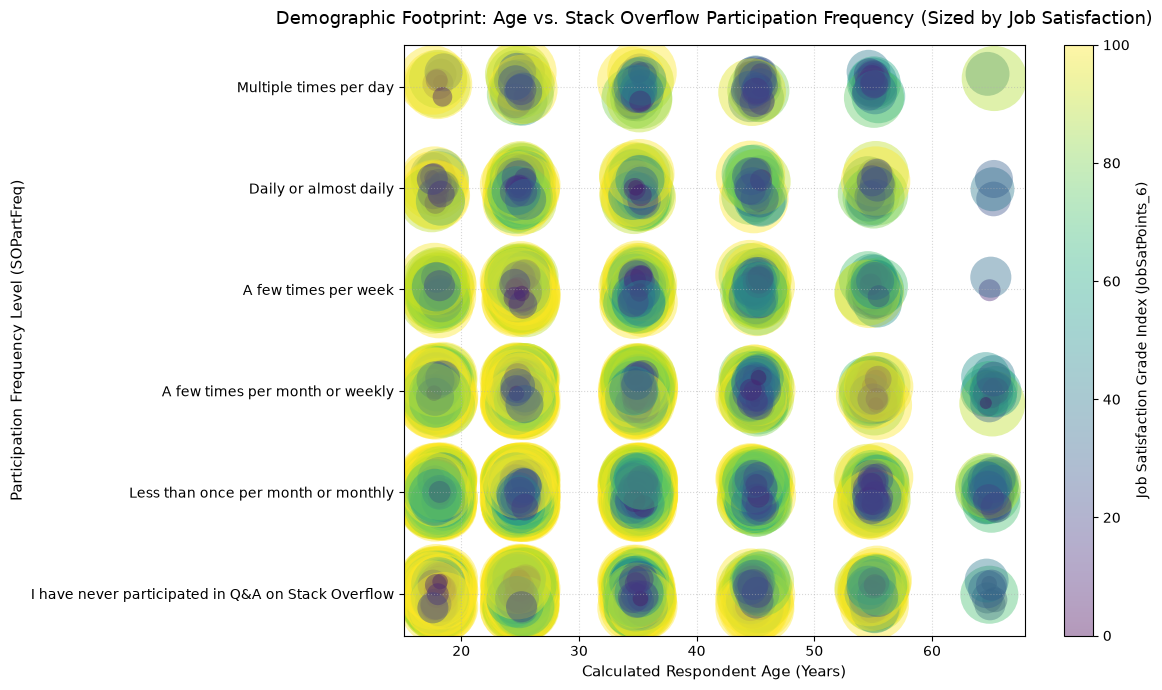

In [6]:
# 1. Parse numeric age out of the string ranges
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)

# 2. Extract job satisfaction integers to use as bubble sizing indices
df['JobSat_Numeric'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# 3. Clean and map SOPartFreq category strings to an ordered numeric scale
freq_mapping = {
    'Multiple times per day': 5,
    'Daily or almost daily': 4,
    'A few times per week': 3,
    'A few times per month or weekly': 2,
    'Less than once per month or monthly': 1,
    'I have never participated in Q&A on Stack Overflow': 0
}
df['PartFreq_Numeric'] = df['SOPartFreq'].map(freq_mapping)

# Drop missing values across all three target dimensional arrays
df_bubble = df.dropna(subset=['Age_Numeric', 'PartFreq_Numeric', 'JobSat_Numeric']).copy()

plt.figure(figsize=(12, 7))

# Introduce slight random noise (jitter) to prevent perfectly stacked bubbles
numpy_rand = pd.Series(df_bubble.index).apply(lambda x: pd.Series(df_bubble.loc[x].name)) # structural anchor
import numpy as np
x_jitter = df_bubble['Age_Numeric'] + np.random.uniform(-0.5, 0.5, size=len(df_bubble))
y_jitter = df_bubble['PartFreq_Numeric'] + np.random.uniform(-0.15, 0.15, size=len(df_bubble))

# Scale up bubble sizes proportionally so changes in job satisfaction stand out
bubble_sizes = df_bubble['JobSat_Numeric'] * 25

# Generate the bubble plot mapping 's' to size and 'c' to the numeric frequency tracking index
scatter = plt.scatter(
    x=x_jitter,
    y=y_jitter,
    s=bubble_sizes,
    c=df_bubble['JobSat_Numeric'], # Color gradient mirrors job satisfaction scaling
    cmap='viridis',
    alpha=0.4,
    edgecolors='none'
)

# Explicitly re-apply human-readable categorical labels on the Y-axis
plt.yticks(list(freq_mapping.values()), list(freq_mapping.keys()))

# Customizing plot visuals
plt.title('Demographic Footprint: Age vs. Stack Overflow Participation Frequency (Sized by Job Satisfaction)', fontsize=13, pad=15)
plt.xlabel('Calculated Respondent Age (Years)', fontsize=11)
plt.ylabel('Participation Frequency Level (SOPartFreq)', fontsize=11)

# Embed a legend colorbar displaying job satisfaction size anchors
cbar = plt.colorbar(scatter)
cbar.set_label('Job Satisfaction Grade Index (JobSatPoints_6)', fontsize=10)

plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


#### 2. Bubble Plot for Compensation vs. Job Satisfaction


-Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSat`).

- Use the size of the bubbles to represent respondents’ age.


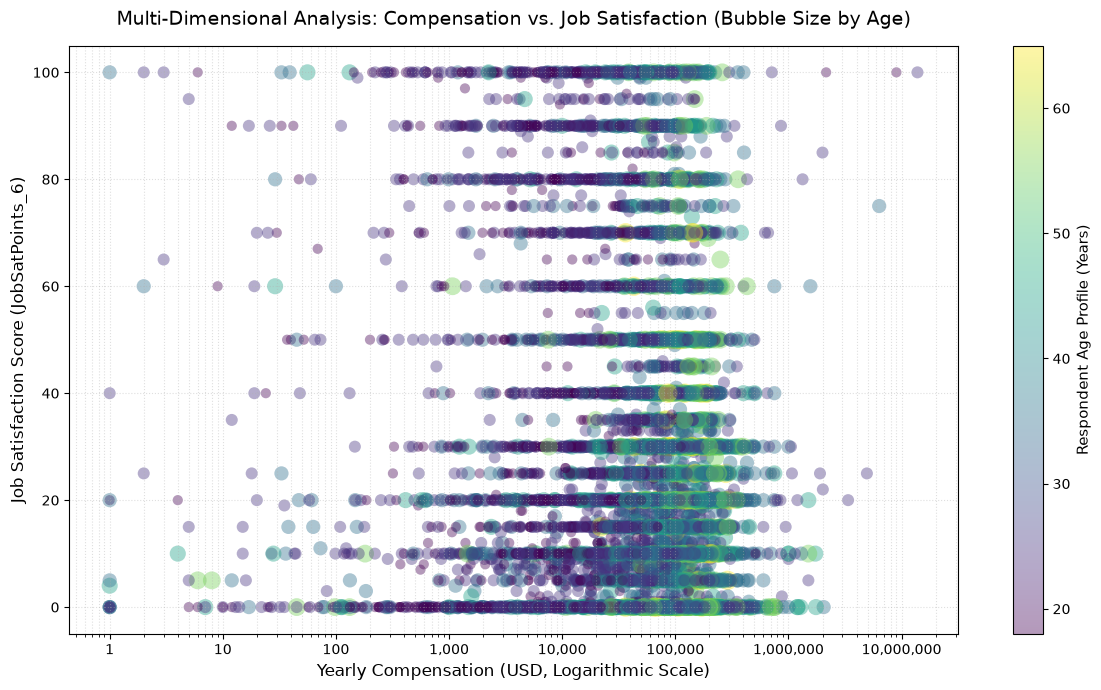

In [7]:
# Enforce clean numeric data structures across our three target fields
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Isolate columns and remove rows with missing entries
df_bubble = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'Age_Numeric']).copy()

plt.figure(figsize=(12, 7))

# Generate the bubble plot mapping 's' to age footprint and 'c' to age color gradient
scatter = plt.scatter(
    x=df_bubble['ConvertedCompYearly'],
    y=df_bubble['JobSatPoints_6'],
    s=df_bubble['Age_Numeric'] * 3.0,     # Adjust multiplier if bubbles appear too large/small
    c=df_bubble['Age_Numeric'],           # Colors the bubbles according to the age gradient
    cmap='viridis',                       # Clean, academic color map gradient
    alpha=0.4,                            # Semi-transparency shows stacked data intersections
    edgecolors='none'
)

# Apply a log scale to handle high-earning salary outliers smoothly
plt.xscale('log')

# Format x-axis integers with commas instead of scientific notation strings
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Text alignments and labels
plt.title('Multi-Dimensional Analysis: Compensation vs. Job Satisfaction (Bubble Size by Age)', fontsize=14, pad=15)
plt.xlabel('Yearly Compensation (USD, Logarithmic Scale)', fontsize=12)
plt.ylabel('Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

# Embed a colorbar to act as a visual key for the bubble dimensions
cbar = plt.colorbar(scatter)
cbar.set_label('Respondent Age Profile (Years)', fontsize=11)

plt.grid(True, which="both", linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()


### Task 2: Analyzing Relationships Using Bubble Plots


#### 1. Bubble Plot of Technology Preferences by Age

- Visualize the popularity of programming languages respondents have worked with (`LanguageHaveWorkedWith`) across age groups.

- Use bubble size to represent the frequency of each language.



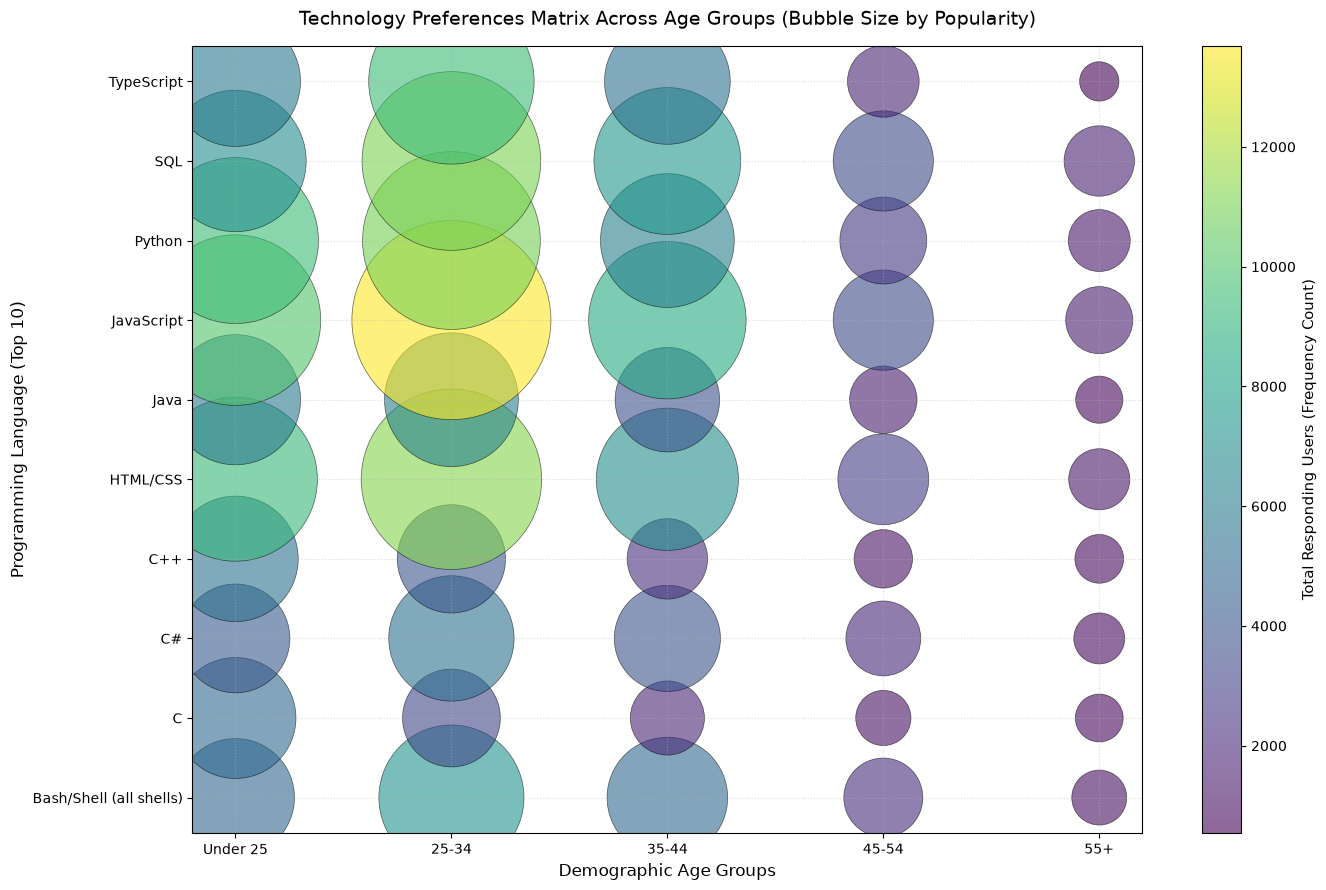

In [8]:


# 1. Clean Age and create categorical Age Groups
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float) #
age_bins = [0, 24, 34, 44, 54, 100] #
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+'] #
df['AgeGroup'] = pd.cut(df['Age_Numeric'], bins=age_bins, labels=age_labels) #

# 2. Drop rows missing crucial fields
df_lang = df.dropna(subset=['LanguageHaveWorkedWith', 'AgeGroup']).copy() #

# 3. Split the semicolon-separated string into a list and explode rows
df_lang['LanguageHaveWorkedWith'] = df_lang['LanguageHaveWorkedWith'].str.split(';') #
df_exploded = df_lang.explode('LanguageHaveWorkedWith') #

# 4. Aggregate to find the frequency (count) of each language per age group (FIXED WITH OBSERVED=TRUE)
lang_age_stats = df_exploded.groupby(['AgeGroup', 'LanguageHaveWorkedWith'], observed=True).size().reset_index(name='Frequency')

# 5. Filter for the Top 10 overall most popular languages to keep the chart clean
top_10_langs = df_exploded['LanguageHaveWorkedWith'].value_counts().nlargest(10).index #
df_filtered = lang_age_stats[lang_age_stats['LanguageHaveWorkedWith'].isin(top_10_langs)].copy() #

# 6. Initialize Visual Canvas Layout
plt.figure(figsize=(14, 9)) #

# Scale up bubble sizes so user differences stand out clearly on screen
bubble_sizes = df_filtered['Frequency'] * 1.5 #

# Generate the categorical bubble plot grid
scatter = plt.scatter( #
    x=df_filtered['AgeGroup'], #
    y=df_filtered['LanguageHaveWorkedWith'], #
    s=bubble_sizes, #
    c=df_filtered['Frequency'], # Color maps to density popularity gradient
    cmap='viridis', #
    alpha=0.6, #
    edgecolors='black', #
    linewidths=0.5 #
) #

# Text, titles, and layout formatting
plt.title('Technology Preferences Matrix Across Age Groups (Bubble Size by Popularity)', fontsize=14, pad=15) #
plt.xlabel('Demographic Age Groups', fontsize=12) #
plt.ylabel('Programming Language (Top 10)', fontsize=12) #

# Embed a colorbar legend to represent the volume scale of developers
cbar = plt.colorbar(scatter) #
cbar.set_label('Total Responding Users (Frequency Count)', fontsize=11) #

plt.grid(True, linestyle=':', alpha=0.5) #
plt.tight_layout() #
plt.show() #


#### 2. Bubble Plot for Preferred Databases vs. Job Satisfaction

- Explore the relationship between preferred databases (`DatabaseWantToWorkWith`) and job satisfaction.

- Use bubble size to indicate the number of respondents for each database.


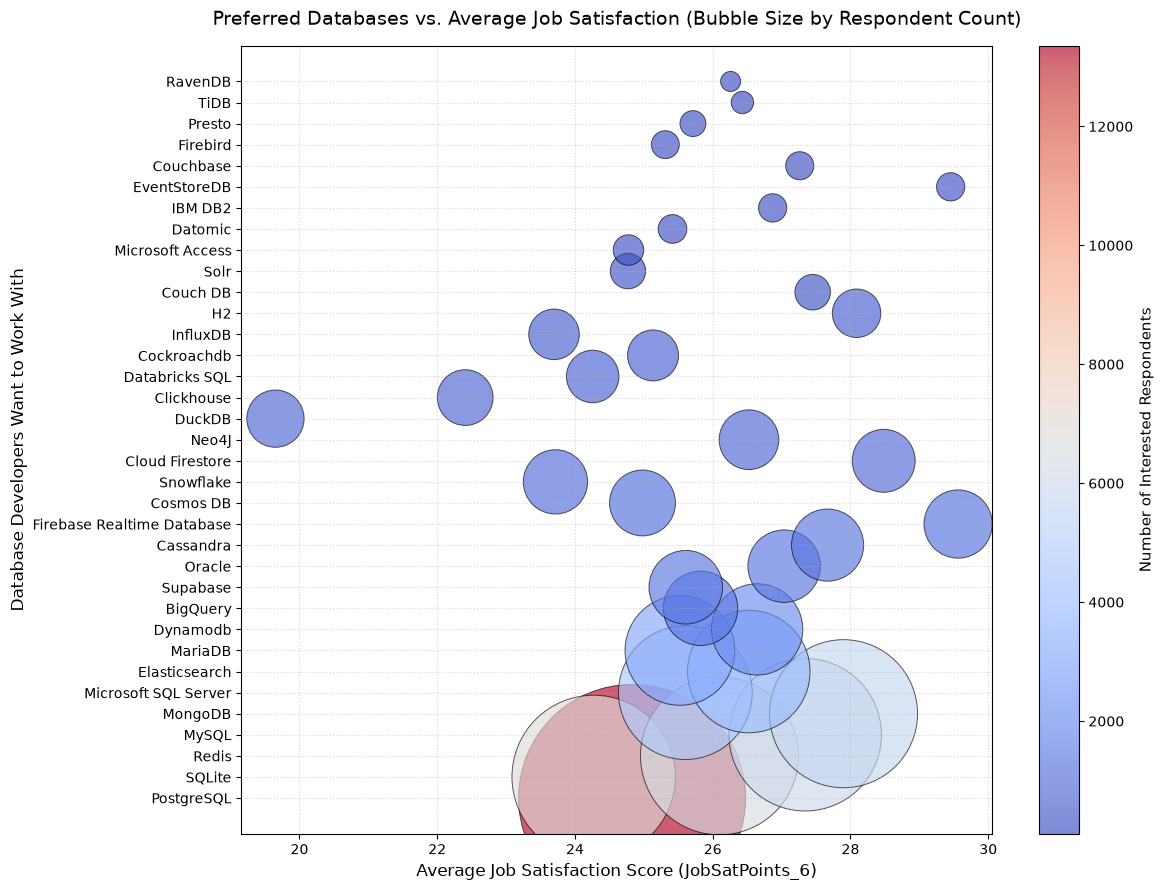

In [9]:
# Enforce clean numeric data structures for job satisfaction
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop missing values across our target evaluation columns
df_db = df.dropna(subset=['DatabaseWantToWorkWith', 'JobSatPoints_6']).copy()

# 1. Split the semi-colon strings into Python lists
df_db['DatabaseWantToWorkWith'] = df_db['DatabaseWantToWorkWith'].str.split(';')

# 2. Explode the lists so each unique database gets its own row matching its satisfaction score
df_exploded = df_db.explode('DatabaseWantToWorkWith')

# 3. Group by database to isolate mean satisfaction and total user footprint counts
db_stats = df_exploded.groupby('DatabaseWantToWorkWith').agg(
    Avg_Satisfaction=('JobSatPoints_6', 'mean'),
    Respondent_Count=('JobSatPoints_6', 'count')
).reset_index()

# 4. Sort by popularity to keep tracking uniform or filter if needed
db_stats.sort_values(by='Respondent_Count', ascending=False, inplace=True)

plt.figure(figsize=(12, 9))

# Scale up bubble sizes proportionally for high-visibility differentiation on canvas
bubble_sizes = db_stats['Respondent_Count'] * 2.0

# Generate the bubble plot mapping 's' to respondent frequency footprint
scatter = plt.scatter(
    x=db_stats['Avg_Satisfaction'],
    y=db_stats['DatabaseWantToWorkWith'],
    s=bubble_sizes,
    c=db_stats['Respondent_Count'],    # Optional color gradient mirroring database popularity
    cmap='coolwarm',
    alpha=0.65,
    edgecolors='black',
    linewidths=0.7
)

# Text, titles, and layout properties
plt.title('Preferred Databases vs. Average Job Satisfaction (Bubble Size by Respondent Count)', fontsize=14, pad=15)
plt.xlabel('Average Job Satisfaction Score (JobSatPoints_6)', fontsize=12)
plt.ylabel('Database Developers Want to Work With', fontsize=12)

# Embed a colorbar to serve as a scannable population key
cbar = plt.colorbar(scatter)
cbar.set_label('Number of Interested Respondents', fontsize=11)

plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Task 3: Comparing Data Using Bubble Plots


#### 1. Bubble Plot for Compensation Across Developer Roles

- Visualize compensation (`ConvertedCompYearly`) across different developer roles (`DevType`).

- Use bubble size to represent job satisfaction.


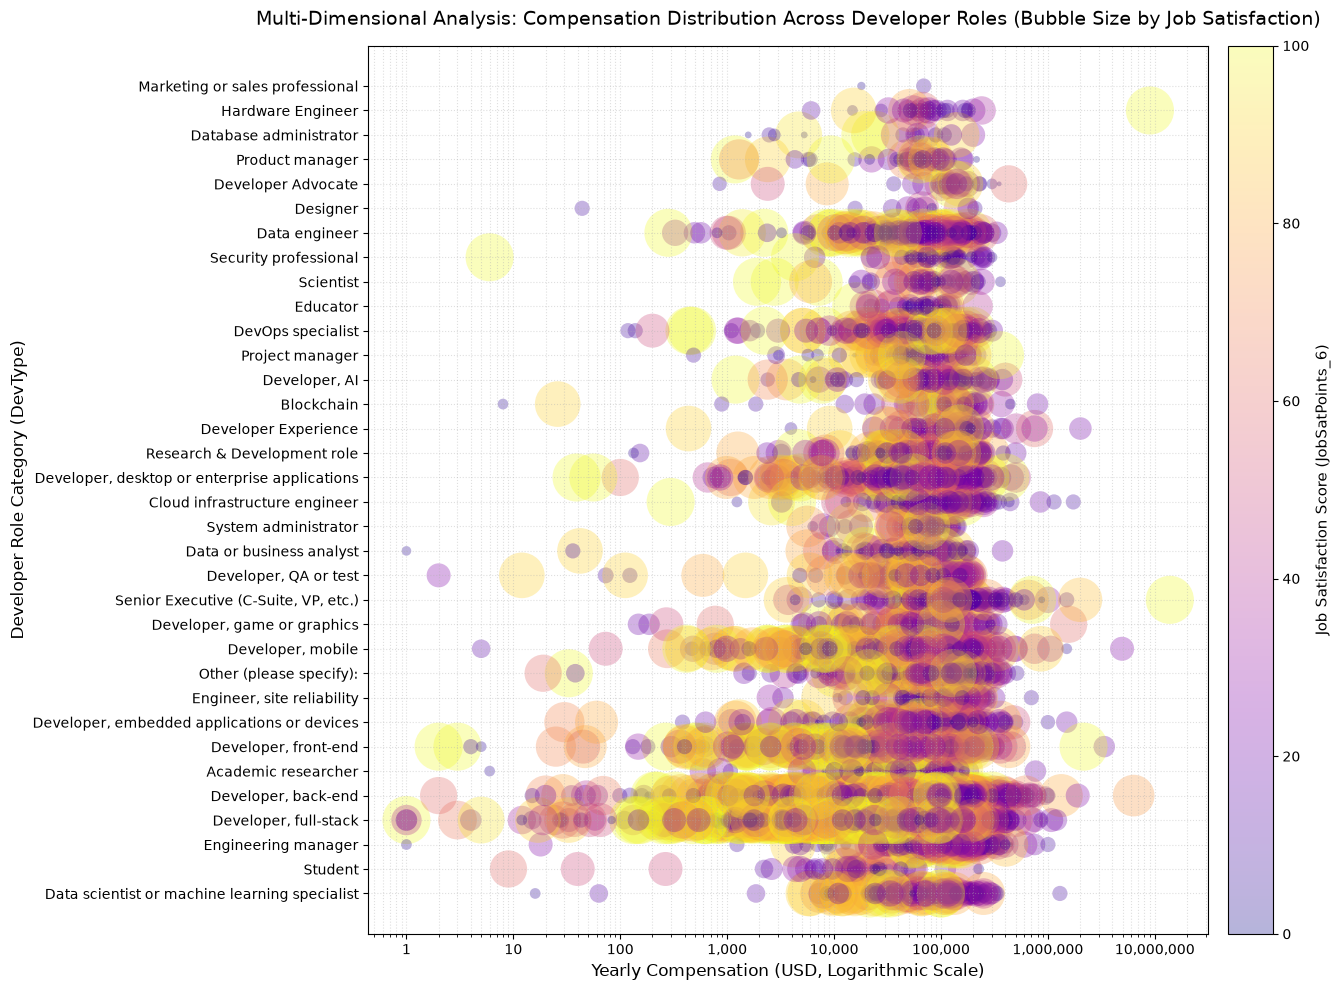

In [10]:
# Enforce clean numeric types for tracking variables
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop rows missing crucial metrics
df_dev = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'DevType']).copy()

# Split the semi-colon strings into Python lists and explode into distinct rows
df_dev['DevType'] = df_dev['DevType'].str.split(';')
df_exploded = df_dev.explode('DevType')

plt.figure(figsize=(14, 10))

# Scale up bubble sizes proportionally so variations stand out clearly
bubble_sizes = df_exploded['JobSatPoints_6'] * 12.0

# Generate the bubble plot mapping 's' to satisfaction footprint
scatter = plt.scatter(
    x=df_exploded['ConvertedCompYearly'],
    y=df_exploded['DevType'],
    s=bubble_sizes,
    c=df_exploded['JobSatPoints_6'],    # Colors bubbles according to satisfaction score 
    cmap='plasma',                      # High-contrast visual color gradient
    alpha=0.3,                          # Transparency allows visibility of packed points
    edgecolors='none'
)

# Apply a log scale to pull apart dense clusters of compensation numbers
plt.xscale('log')

# Format x-axis integers with commas instead of scientific notation strings
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Text alignments and labels
plt.title('Multi-Dimensional Analysis: Compensation Distribution Across Developer Roles (Bubble Size by Job Satisfaction)', fontsize=14, pad=15)
plt.xlabel('Yearly Compensation (USD, Logarithmic Scale)', fontsize=12)
plt.ylabel('Developer Role Category (DevType)', fontsize=12)

# Embed a colorbar to act as a visual legend for the job satisfaction gradient
cbar = plt.colorbar(scatter, pad=0.02)
cbar.set_label('Job Satisfaction Score (JobSatPoints_6)', fontsize=11)

plt.grid(True, which="both", linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()


#### 2. Bubble Plot for Collaboration Tools by Age

- Visualize the relationship between the collaboration tools used (`NEWCollabToolsHaveWorkedWith`) and age groups.

- Use bubble size to represent the frequency of tool usage.


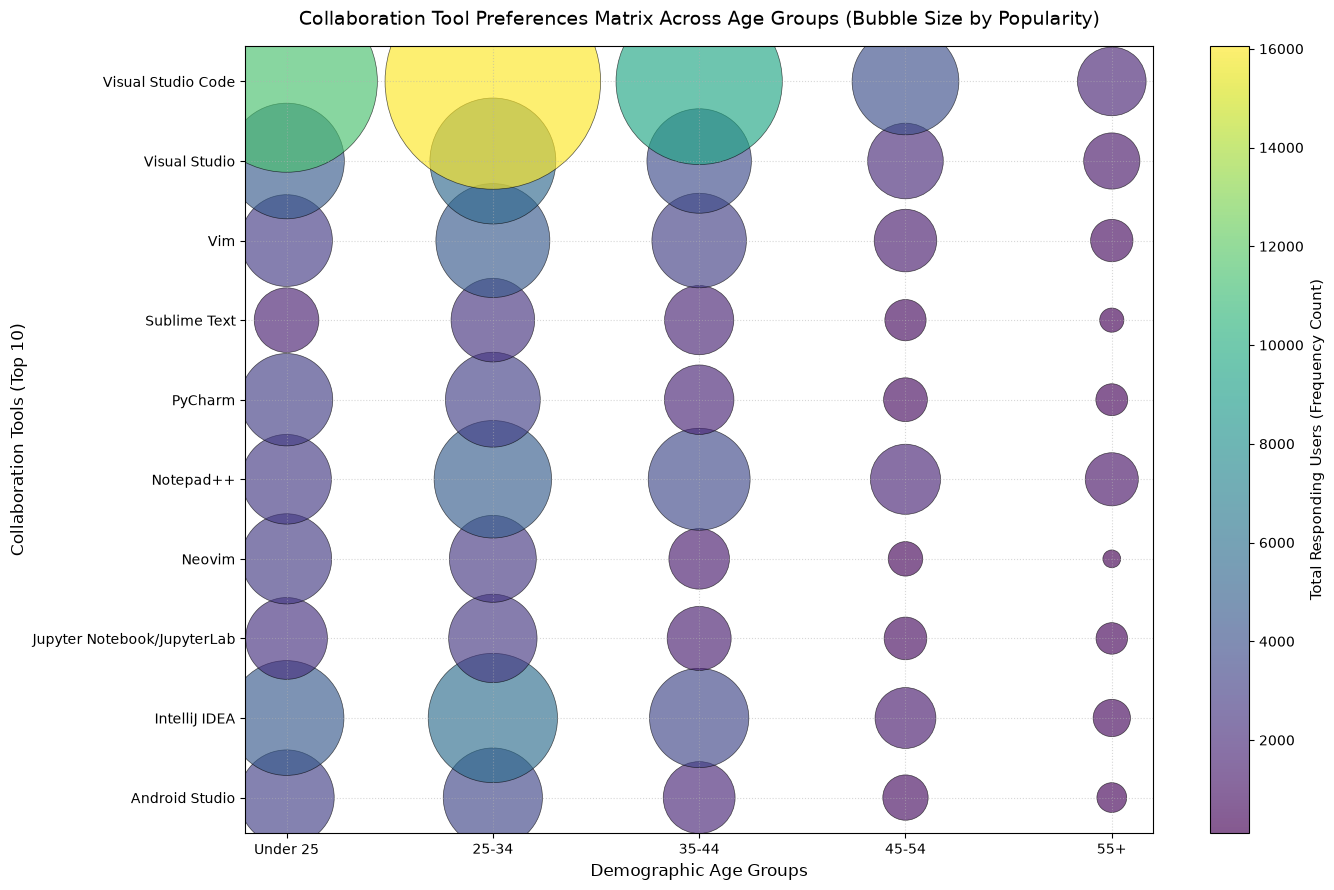

In [11]:
# 1. Clean Age and create categorical Age Groups
df['Age_Numeric'] = df['Age'].str.extract(r'(\d+)').astype(float)
age_bins = [0, 24, 34, 44, 54, np.inf]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']
df['AgeGroup'] = pd.cut(df['Age_Numeric'], bins=age_bins, labels=age_labels)

# 2. Drop rows missing crucial fields
df_tools = df.dropna(subset=['NEWCollabToolsHaveWorkedWith', 'AgeGroup']).copy()

# 3. Split the semicolon-separated string into a list and explode rows
df_tools['NEWCollabToolsHaveWorkedWith'] = df_tools['NEWCollabToolsHaveWorkedWith'].str.split(';')
df_exploded = df_tools.explode('NEWCollabToolsHaveWorkedWith')

# 4. Aggregate to find the frequency (count) of each tool per age group
tools_age_stats = df_exploded.groupby(['AgeGroup', 'NEWCollabToolsHaveWorkedWith'], observed=False).size().reset_index(name='Frequency')

# 5. Filter for the Top 10 overall most popular tools to keep the chart clean and readable
top_10_tools = df_exploded['NEWCollabToolsHaveWorkedWith'].value_counts().nlargest(10).index
df_filtered = tools_age_stats[tools_age_stats['NEWCollabToolsHaveWorkedWith'].isin(top_10_tools)].copy()

plt.figure(figsize=(14, 9))

# Scale up bubble sizes proportionally so variations stand out clearly on screen
bubble_sizes = df_filtered['Frequency'] * 1.5

# Generate the categorical bubble plot grid
scatter = plt.scatter(
    x=df_filtered['AgeGroup'],
    y=df_filtered['NEWCollabToolsHaveWorkedWith'],
    s=bubble_sizes,
    c=df_filtered['Frequency'],       # Color maps to popularity density gradient
    cmap='viridis',
    alpha=0.65,
    edgecolors='black',
    linewidths=0.5
)

# Text, titles, and layout formatting
plt.title('Collaboration Tool Preferences Matrix Across Age Groups (Bubble Size by Popularity)', fontsize=14, pad=15)
plt.xlabel('Demographic Age Groups', fontsize=12)
plt.ylabel('Collaboration Tools (Top 10)', fontsize=12)

# Embed a colorbar legend to represent the volume scale of developers
cbar = plt.colorbar(scatter)
cbar.set_label('Total Responding Users (Frequency Count)', fontsize=11)

plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### Task 4: Visualizing Technology Trends Using Bubble Plots


#### 1. Bubble Plot for Preferred Web Frameworks vs. Job Satisfaction

- Explore the relationship between preferred web frameworks (`WebframeWantToWorkWith`) and job satisfaction.

- Use bubble size to represent the number of respondents.



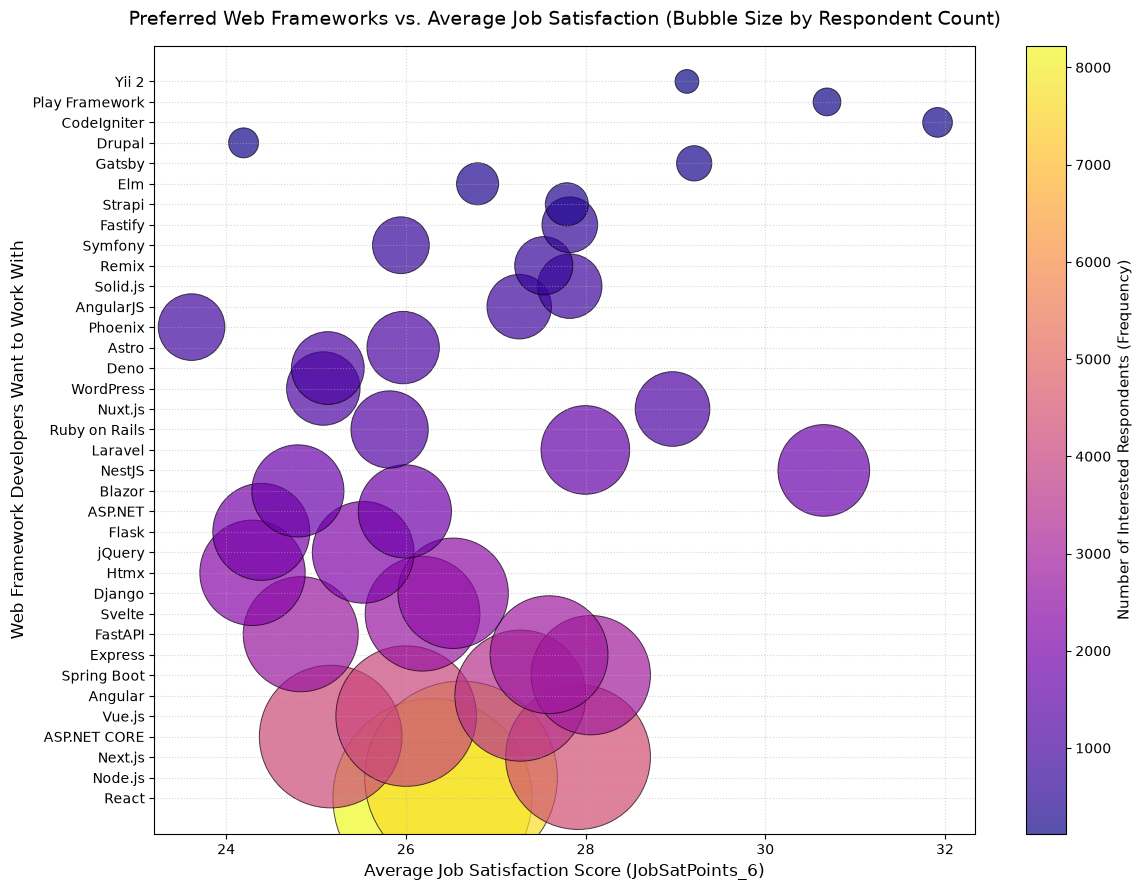

In [12]:
# Enforce clean numeric data structures for job satisfaction metric
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Remove entries missing values in our target columns
df_wf = df.dropna(subset=['WebframeWantToWorkWith', 'JobSatPoints_6']).copy()

# 1. Split the semi-colon strings into clear lists
df_wf['WebframeWantToWorkWith'] = df_wf['WebframeWantToWorkWith'].str.split(';')

# 2. Explode the lists so each web framework maps to its own row alongside the satisfaction score
df_exploded = df_wf.explode('WebframeWantToWorkWith')

# 3. Group by web framework to extract mean satisfaction and user counts
wf_stats = df_exploded.groupby('WebframeWantToWorkWith').agg(
    Avg_Satisfaction=('JobSatPoints_6', 'mean'),
    Respondent_Count=('JobSatPoints_6', 'count')
).reset_index()

# Sort frameworks by popularity to keep tracking clean
wf_stats.sort_values(by='Respondent_Count', ascending=False, inplace=True)

plt.figure(figsize=(12, 9))

# Scale up bubble sizes proportionally for visibility on screen
bubble_sizes = wf_stats['Respondent_Count'] * 2.5

# Generate the bubble plot mapping 's' to user popularity footprints
scatter = plt.scatter(
    x=wf_stats['Avg_Satisfaction'],
    y=wf_stats['WebframeWantToWorkWith'],
    s=bubble_sizes,
    c=wf_stats['Respondent_Count'],    # Color maps to popularity density gradient
    cmap='plasma',
    alpha=0.7,
    edgecolors='black',
    linewidths=0.7
)

# Text configurations and visual layouts
plt.title('Preferred Web Frameworks vs. Average Job Satisfaction (Bubble Size by Respondent Count)', fontsize=14, pad=15)
plt.xlabel('Average Job Satisfaction Score (JobSatPoints_6)', fontsize=12)
plt.ylabel('Web Framework Developers Want to Work With', fontsize=12)

# Embed a colorbar to act as a scannable population key
cbar = plt.colorbar(scatter)
cbar.set_label('Number of Interested Respondents (Frequency)', fontsize=11)

plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


#### 2. Bubble Plot for Admired Technologies Across Countries

- Visualize the distribution of admired technologies (`LanguageAdmired`) across different countries (`Country`).

- Use bubble size to represent the frequency of admiration.



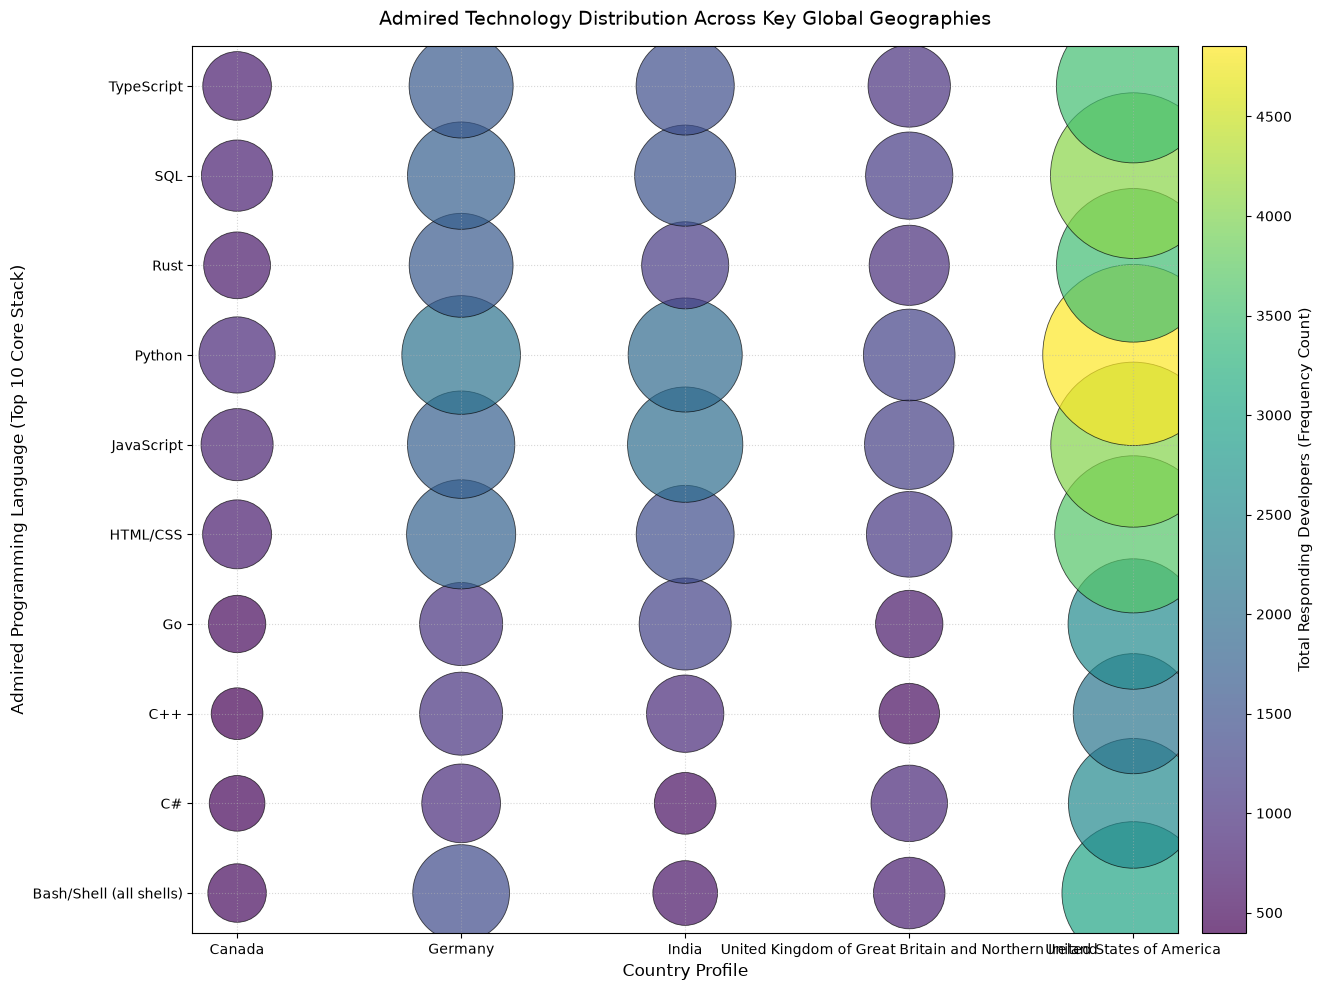

In [13]:
# 1. Clean the key text fields, dropping empty entries
# Note: In Stack Overflow survey structures, 'LanguageWantToWorkWith' corresponds to admired/desired technologies.
df_admired = df.dropna(subset=['LanguageWantToWorkWith', 'Country']).copy()

# 2. Split the semicolon strings into clear Python lists
df_admired['LanguageWantToWorkWith'] = df_admired['LanguageWantToWorkWith'].str.split(';')

# 3. Explode the lists so each unique language gets its own row matching its country
df_exploded = df_admired.explode('LanguageWantToWorkWith')

# 4. Filter for Top 5 Countries and Top 10 Languages to prevent chaotic chart crowding
top_5_countries = df_exploded['Country'].value_counts().nlargest(5).index
top_10_languages = df_exploded['LanguageWantToWorkWith'].value_counts().nlargest(10).index

df_filtered = df_exploded[
    df_exploded['Country'].isin(top_5_countries) & 
    df_exploded['LanguageWantToWorkWith'].isin(top_10_languages)
].copy()

# 5. Group by Country and Language to find the absolute frequency of admiration counts
geo_stats = df_filtered.groupby(['Country', 'LanguageWantToWorkWith']).size().reset_index(name='Frequency')

plt.figure(figsize=(14, 10))

# Scale up bubble sizes proportionally for high-visibility differentiation on the canvas
bubble_sizes = geo_stats['Frequency'] * 3.5

# Generate the categorical bubble plot grid matrix
scatter = plt.scatter(
    x=geo_stats['Country'],
    y=geo_stats['LanguageWantToWorkWith'],
    s=bubble_sizes,
    c=geo_stats['Frequency'],          # Color maps directly to the popularity scale
    cmap='viridis',                    # High-contrast color gradient mapping profile
    alpha=0.7,                         # Translucency handles closely situated bubble edges
    edgecolors='black',
    linewidths=0.6
)

# Text configurations and visual properties
plt.title('Admired Technology Distribution Across Key Global Geographies', fontsize=14, pad=15)
plt.xlabel('Country Profile', fontsize=12)
plt.ylabel('Admired Programming Language (Top 10 Core Stack)', fontsize=12)

# Embed a colorbar to serve as a scannable volume legend
cbar = plt.colorbar(scatter, pad=0.02)
cbar.set_label('Total Responding Developers (Frequency Count)', fontsize=11)

plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


## Final Step: Review


After completing the lab, you will have extensively used bubble plots to gain insights into developer community preferences, demographics, compensation trends, and job satisfaction.


## Summary


After completing this lab, you will be able to:

- Create and interpret bubble plots to analyze relationships and compositions within datasets.

- Use bubble plots to explore developer preferences, compensation trends, and satisfaction levels.

- Apply bubble plots to visualize complex relationships involving multiple dimensions effectively.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-29|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
